In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('dirty_cafe_sales.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


In [4]:
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [5]:
df.isnull().sum()

Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64

In [6]:
df['Item'].unique()

<StringArray>
[  'Coffee',     'Cake',   'Cookie',    'Salad', 'Smoothie',  'UNKNOWN',
 'Sandwich',        nan,    'ERROR',    'Juice',      'Tea']
Length: 11, dtype: str

In [7]:
df['Item'].value_counts()

Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
ERROR        292
Name: count, dtype: int64

In [8]:
import numpy as np

In [9]:
df = df.replace( ['UNKNOWN', "ERROR"] ,np.nan)

In [10]:
df['Item'].value_counts()

Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
Name: count, dtype: int64

In [11]:
df.isnull().sum()

Transaction ID         0
Item                 969
Quantity             479
Price Per Unit       533
Total Spent          502
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64

In [12]:
df['Price Per Unit'].unique()

<StringArray>
['2.0', '3.0', '1.0', '5.0', '4.0', '1.5', nan]
Length: 7, dtype: str

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9031 non-null   str  
 2   Quantity          9521 non-null   str  
 3   Price Per Unit    9467 non-null   str  
 4   Total Spent       9498 non-null   str  
 5   Payment Method    6822 non-null   str  
 6   Location          6039 non-null   str  
 7   Transaction Date  9540 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


In [14]:
df['Quantity'] = pd.to_numeric(df['Quantity'])

In [15]:
df['Price Per Unit'] = pd.to_numeric(df['Price Per Unit'])

In [16]:
df['Total Spent'] = pd.to_numeric(df['Total Spent'])

In [17]:
df.groupby('Item')['Price Per Unit'].unique()

Item
Cake        [3.0, nan]
Coffee      [2.0, nan]
Cookie      [1.0, nan]
Juice       [3.0, nan]
Salad       [5.0, nan]
Sandwich    [4.0, nan]
Smoothie    [4.0, nan]
Tea         [1.5, nan]
Name: Price Per Unit, dtype: object

In [18]:
price_to_item = {1.0:'Cookie' ,1.5: 'Tea' , 2.0:'Coffee' , 5.0:'Salad'}

In [19]:
df['Item'] = df['Item'].fillna(df['Price Per Unit'].map(price_to_item))

In [20]:
df['Price Per Unit'] = df['Price Per Unit'].fillna(df.groupby('Item')['Price Per Unit'].transform('first'))

In [21]:
df.isnull().sum()

Transaction ID         0
Item                 501
Quantity             479
Price Per Unit        54
Total Spent          502
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    10000 non-null  str    
 1   Item              9499 non-null   str    
 2   Quantity          9521 non-null   float64
 3   Price Per Unit    9946 non-null   float64
 4   Total Spent       9498 non-null   float64
 5   Payment Method    6822 non-null   str    
 6   Location          6039 non-null   str    
 7   Transaction Date  9540 non-null   str    
dtypes: float64(3), str(5)
memory usage: 625.1 KB


In [23]:
df['Price Per Unit'] = df['Price Per Unit'].fillna(df['Total Spent']/df['Quantity'])

In [24]:
df['Item'] = df['Item'].fillna(df['Price Per Unit'].map(price_to_item))

In [25]:
df.isnull().sum()

Transaction ID         0
Item                 480
Quantity             479
Price Per Unit         6
Total Spent          502
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64

In [26]:
df['Item'].unique()

<StringArray>
[  'Coffee',     'Cake',   'Cookie',    'Salad', 'Smoothie',        nan,
 'Sandwich',      'Tea',    'Juice']
Length: 9, dtype: str

In [27]:
df['Total Spent'] = df['Total Spent'].fillna(df['Price Per Unit'] * df['Quantity'])

In [28]:
df['Quantity'] = df['Quantity'].fillna(df['Total Spent'] / df['Price Per Unit'])

In [29]:
df['Item'] = df['Item'].fillna(df['Price Per Unit'].map(price_to_item))

In [30]:
df.isnull().sum()

Transaction ID         0
Item                 480
Quantity              23
Price Per Unit         6
Total Spent           23
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64

In [31]:
df = df.dropna(subset=['Quantity' , 'Price Per Unit', 'Total Spent'])

In [32]:
df.isnull().sum()

Transaction ID         0
Item                 474
Quantity               0
Price Per Unit         0
Total Spent            0
Payment Method      3168
Location            3952
Transaction Date     460
dtype: int64

In [33]:
df['Item'] = df['Item'].fillna('UNKNOWN')

In [34]:
df['Payment Method'] = df['Payment Method'].fillna('UNKNOWN')

In [35]:
df['Location'] = df['Location'].fillna('UNKNOWN')

In [36]:
df.isnull().sum()

Transaction ID        0
Item                  0
Quantity              0
Price Per Unit        0
Total Spent           0
Payment Method        0
Location              0
Transaction Date    460
dtype: int64

In [37]:
df['Transaction Date'].unique()

<StringArray>
['2023-09-08', '2023-05-16', '2023-07-19', '2023-04-27', '2023-06-11',
 '2023-03-31', '2023-10-06', '2023-10-28', '2023-07-28', '2023-12-31',
 ...
 '2023-08-01', '2023-01-20', '2023-11-11', '2023-02-13', '2023-07-30',
 '2023-02-17', '2023-05-20', '2023-11-05', '2023-03-27', '2023-07-03']
Length: 366, dtype: str

In [38]:
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'])

In [39]:
df['Transaction Date'].unique()

<DatetimeArray>
['2023-09-08 00:00:00', '2023-05-16 00:00:00', '2023-07-19 00:00:00',
 '2023-04-27 00:00:00', '2023-06-11 00:00:00', '2023-03-31 00:00:00',
 '2023-10-06 00:00:00', '2023-10-28 00:00:00', '2023-07-28 00:00:00',
 '2023-12-31 00:00:00',
 ...
 '2023-08-01 00:00:00', '2023-01-20 00:00:00', '2023-11-11 00:00:00',
 '2023-02-13 00:00:00', '2023-07-30 00:00:00', '2023-02-17 00:00:00',
 '2023-05-20 00:00:00', '2023-11-05 00:00:00', '2023-03-27 00:00:00',
 '2023-07-03 00:00:00']
Length: 366, dtype: datetime64[us]

In [40]:
df.isnull().sum()

Transaction ID        0
Item                  0
Quantity              0
Price Per Unit        0
Total Spent           0
Payment Method        0
Location              0
Transaction Date    460
dtype: int64

In [41]:
(df['Total Spent'] != df['Quantity'] * df['Price Per Unit']).sum()

np.int64(0)

In [42]:
df.to_csv('cleaned_cafe_sales.csv', index=False)

In [43]:
revenue = df.groupby('Item')['Total Spent'].sum().sort_values(ascending=False)
revenue

Item
Salad       19095.0
Sandwich    13716.0
Smoothie    13344.0
Juice       10515.0
Cake        10404.0
Coffee       7808.0
Tea          5475.0
UNKNOWN      5087.0
Cookie       3598.0
Name: Total Spent, dtype: float64

In [44]:
import matplotlib.pyplot as plt

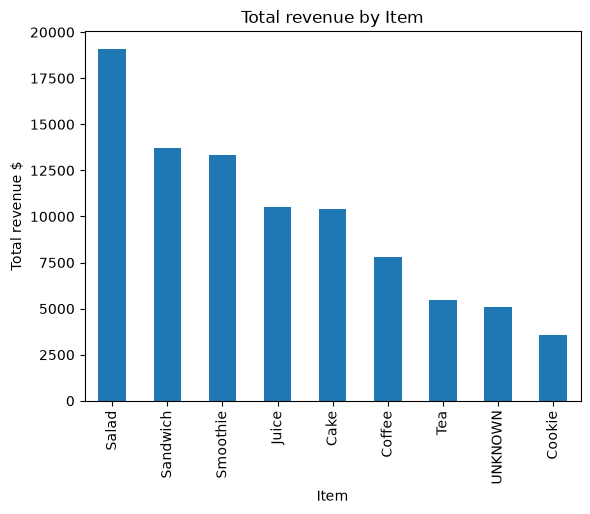

In [45]:
revenue.plot(kind='bar')
plt.title('Total revenue by Item')
plt.xlabel('Item')
plt.ylabel('Total revenue $')
plt.savefig('total_revenue.png', bbox_inches='tight')
plt.show()

In [46]:
units_sold = df.groupby('Item')['Quantity'].sum().sort_values(ascending=False)
units_sold

Item
Coffee      3904.0
Salad       3819.0
Tea         3650.0
Cookie      3598.0
Juice       3505.0
Cake        3468.0
Sandwich    3429.0
Smoothie    3336.0
UNKNOWN     1461.0
Name: Quantity, dtype: float64

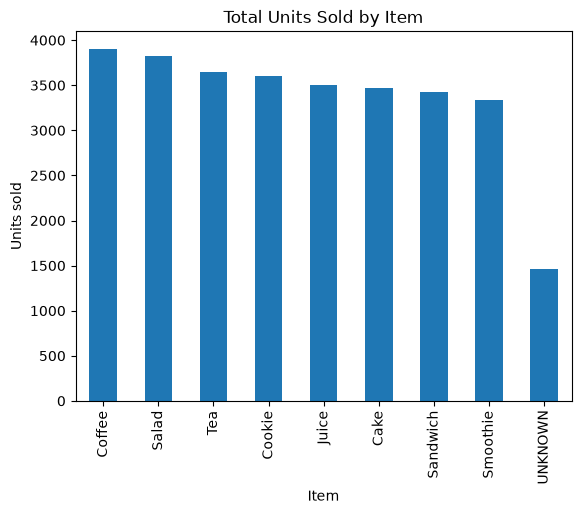

In [47]:
units_sold.plot(kind='bar')
plt.title('Total Units Sold by Item')
plt.xlabel('Item')
plt.ylabel('Units sold')
plt.savefig('units_sold.png', bbox_inches='tight')
plt.show()